# Notebook 03. Method Test on Business Invoices

**Project:** Ensemble Machine Learning for Mitigating Payment Paralysis in Kenyan Small and Medium Enterprises: A Decision Support Prototype
**Researcher:** Sandra Minoo Mbithi (167253)
**Supervisor:** Dr. Allan Omondi

## Purpose
This notebook runs the same method used in notebook 01 on real business to business invoices. It does not reuse the notebook 01 model. The same steps are repeated on new data to check whether the method still works when the data looks like what the prototype stores.

## Data
Customer invoice dataset from Kaggle (50,000 invoices from a large company). Each row is one invoice with an issue date, a due date, a payment date and an amount.

## Target
An invoice is late if it was paid after its due date. This is the same rule used in notebook 01 and in the Laravel system.

## Method
1. Clean the data by removing duplicates, invoices with withheld payment dates and rows with missing values
2. Check for censoring in the later months
3. Build the same history features as notebook 01, using only invoices already paid before each new invoice
4. Split the data by date into training, calibration and test periods
5. Fix the tier cut-offs before seeing any result
6. Tune and compare Logistic Regression, Random Forest, Gradient Boosting, their average and Random Forest with SMOTE
7. Calibrate the chosen model and evaluate it once on the test period
8. Explain the predictions with SHAP

**The same libraries as notebook 01, because this is the same method on different data.**

In [1]:
import os
os.environ['PYTHONWARNINGS'] = 'ignore'
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import shap

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score, f1_score, confusion_matrix,
                             RocCurveDisplay, PrecisionRecallDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

SEED = 42
RAW, MODELS, REPORTS = '../data/raw/', '../models/', '../reports/'
FIGS = REPORTS + 'figures/'
for folder in (MODELS, FIGS):
    os.makedirs(folder, exist_ok=True)
np.random.seed(SEED)
print('Environment ready')

Environment ready


**Load and clean**

Three cleaning steps. Duplicate rows are removed. Masked invoices are removed using the dataset's own open flag, because their payment dates were withheld when the dataset was published, so they have no outcome. Rows with a missing date or amount are removed.

In [2]:
k = pd.read_csv(RAW + 'customer_invoice_kaggle.csv')
print('Rows as downloaded:', len(k))

k = k.drop_duplicates()
print('After removing duplicate rows:', len(k))

k = k[k.isOpen == 0].copy()
print('After removing invoices whose payment date was withheld:', len(k))

def to_date(s):
    return pd.to_datetime(s.astype('Int64').astype(str), format='%Y%m%d', errors='coerce')

k['issued'] = pd.to_datetime(k.posting_date, errors='coerce')
k['due'] = to_date(k.due_in_date)
k['paid'] = pd.to_datetime(k.clear_date, errors='coerce')
k['amount'] = pd.to_numeric(k.total_open_amount, errors='coerce')
k = k.dropna(subset=['issued', 'due', 'paid', 'amount', 'cust_number'])
print('After dropping rows with a missing date or amount:', len(k))

Rows as downloaded: 50000
After removing duplicate rows: 48839
After removing invoices whose payment date was withheld: 39158
After dropping rows with a missing date or amount: 39158


**Identify the target**

The same rule as notebook 01 and the same rule as the Laravel system. An invoice is late if it was paid after its due date. 1 means late, 0 means on time.

In [3]:
k['days_late'] = (k.paid - k.due).dt.days
k['target'] = (k.days_late > 0).astype(int)
k['terms_days'] = (k.due - k.issued).dt.days
print(f'Invoices paid late: {k.target.mean():.1%}')
print(k.days_late.describe().round(1))

Invoices paid late: 41.9%
count    39158.0
mean         0.8
std         10.8
min        -89.0
25%         -3.0
50%          0.0
75%          2.0
max        204.0
Name: days_late, dtype: float64


**The censoring check**


Before trusting any month, check whether the dataset observed long delays in that month. This compares the two possible rules side by side.

In [4]:
by_month = k.groupby(k.issued.dt.to_period('M')).agg(
    invoices=('target', 'size'),
    late_at_all=('target', 'mean'),
    more_than_30_days=('days_late', lambda s: (s > 30).mean()),
    last_payment_seen=('paid', 'max'))
by_month.round(3)

,invoices,late_at_all,more_than_30_days,last_payment_seen
issued,,,,
2018-12,129,0.302,0.031,2019-05-01
2019-01,2650,0.438,0.026,2019-07-10
2019-02,2696,0.455,0.026,2019-08-30
2019-03,3183,0.417,0.028,2019-08-30
2019-04,3088,0.417,0.027,2019-10-24
2019-05,3038,0.415,0.018,2019-10-10
2019-06,2948,0.435,0.024,2019-12-10
2019-07,2927,0.430,0.024,2019-12-26
2019-08,3057,0.425,0.023,2019-12-27


for invoices issued in October and November 2019 the last payment seen is 31 December 2019. Slow payers from those months were removed when the dataset was built, which is why the "more than 30 days" column collapses there while "late at all" stays steady. Write this up as a data quality finding. It is the kind of thing that earns marks.

**Feature engineering**

The same fourteen ideas as notebook 01, rebuilt for invoices. For every invoice, we look back only at the same customer's earlier invoices that had already been paid before this invoice was issued. Invoices paid later are excluded, because the system could not have known about them at that moment.



The code uses running totals rather than the merge in notebook 01. One customer here has 8,762 invoices and a merge of that customer against itself would create more than 76 million rows. Running totals give the same answer and finish in seconds.

| Feature | Meaning | Where the Laravel system gets it |
|---|---|---|
| `amount` | size of this invoice | invoice amount |
| `terms_days` | days given to pay | due date minus issue date |
| `prior_settled` | earlier invoices already paid | invoices with a payment date |
| `prior_late_share` | share of those paid late | late invoices divided by paid invoices |
| `prior_early_share` | share paid more than 3 days early | same idea, early side |
| `prior_avg_days_late` | usual lateness | average of payment date minus due date |
| `prior_max_days_late` | worst lateness | largest of the same |
| `last_days_late` | lateness on the most recent one | most recent paid invoice |
| `last3_late_share` | recent habit | late share of the last three paid invoices |
| `prior_avg_amount` | usual size | average earlier invoice amount |
| `amount_vs_avg` | is this one unusually big? | this amount divided by usual size |
| `days_since_last_paid` | gap since last payment | issue date minus last payment date |
| `relationship_days` | how long we have traded | issue date minus first invoice date |
| `month` | month of the invoice | month of the issue date |

In [5]:
def add_history(inv):
    """For each invoice, summarise the same customer's earlier invoices that were
    already paid before this invoice was issued."""
    settled = (inv[['cust_number', 'paid', 'days_late', 'amount', 'issued']]
               .rename(columns={'issued': 'earlier_issued'})
               .sort_values(['cust_number', 'paid']))
    settled['late'] = (settled.days_late > 0).astype(float)
    settled['early'] = (settled.days_late < -3).astype(float)
    g = settled.groupby('cust_number')
    n = g.cumcount() + 1

    state = pd.DataFrame({
        'cust_number': settled.cust_number,
        'paid': settled.paid,
        'prior_settled': n,
        'prior_late_share': g.late.cumsum() / n,
        'prior_early_share': g.early.cumsum() / n,
        'prior_avg_days_late': g.days_late.cumsum() / n,
        'prior_max_days_late': g.days_late.cummax(),
        'last_days_late': settled.days_late,
        'last3_late_share': g.late.rolling(3, min_periods=1).mean()
                             .reset_index(level=0, drop=True),
        'prior_avg_amount': g.amount.cumsum() / n,
        'last_paid': settled.paid,
        'first_issued': g.earlier_issued.cummin(),
    }).sort_values('paid')

    # match each invoice to the customer's running history as it stood strictly
    # before the invoice was issued
    out = pd.merge_asof(inv.sort_values('issued'), state,
                        left_on='issued', right_on='paid', by='cust_number',
                        direction='backward', allow_exact_matches=False,
                        suffixes=('', '_state'))
    out['prior_settled'] = out.prior_settled.fillna(0)
    out['amount_vs_avg'] = out.amount / out.prior_avg_amount
    out['days_since_last_paid'] = (out.issued - out.last_paid).dt.days
    out['relationship_days'] = (out.issued - out.first_issued).dt.days
    out['month'] = out.issued.dt.month
    return out

FEATURES = ['amount', 'terms_days', 'prior_settled', 'prior_late_share', 'prior_early_share',
            'prior_avg_days_late', 'prior_max_days_late', 'last_days_late', 'last3_late_share',
            'prior_avg_amount', 'amount_vs_avg', 'days_since_last_paid', 'relationship_days', 'month']

data = add_history(k)
print('Invoices with at least one earlier paid invoice:', f'{(data.prior_settled > 0).mean():.1%}')
data[FEATURES].describe().T.round(2)

Invoices with at least one earlier paid invoice: 92.4%


,count,mean,std,min,25%,50%,75%,max
amount,39158.0,32058.09,39585.54,0.79,4681.74,17245.90,46542.09,668593.36
terms_days,39158.0,17.23,10.50,-50.00,15.00,15.00,15.00,120.00
prior_settled,39158.0,1043.37,2037.41,0.00,18.00,119.00,635.75,8453.00
prior_late_share,36174.0,0.41,0.30,0.00,0.18,0.32,0.65,1.00
prior_early_share,36174.0,0.22,0.27,0.00,0.00,0.04,0.53,1.00
prior_avg_days_late,36174.0,0.48,6.97,-50.00,-2.39,0.23,1.50,120.00
prior_max_days_late,36174.0,38.61,39.80,-50.00,6.00,20.00,90.00,204.00
last_days_late,36174.0,0.51,10.69,-75.00,-3.00,0.00,2.00,151.00
last3_late_share,36174.0,0.39,0.38,0.00,0.00,0.33,0.67,1.00
prior_avg_amount,36174.0,31678.91,23400.47,19.32,21498.26,23013.44,44511.98,668593.36


92.4% of invoices have some history, and a summary of fourteen features. The columns with fewer rows are the history ones, empty for a customer's first invoice. That is handled in preprocessing.

**Train, calibration and test split**

split by date, never at random, for the same reason as notebook 01. The test window is November 2019 to February 2020 and a calibration window sits before it so the probabilities can be corrected on data the model never trained on.

In [6]:
train = data[data.issued < '2019-09-01']
calib = data[(data.issued >= '2019-09-01') & (data.issued < '2019-11-01')]
test = data[(data.issued >= '2019-11-01') & (data.issued < '2020-03-01')]
X_train, y_train = train[FEATURES], train.target
X_calib, y_calib = calib[FEATURES], calib.target
X_test, y_test = test[FEATURES], test.target
for name, y in [('train', y_train), ('calibration', y_calib), ('test', y_test)]:
    print(f'{name:12s} {len(y):6d} rows, late rate {y.mean():.1%}')

train         23716 rows, late rate 42.8%
calibration    5944 rows, late rate 41.8%
test           9498 rows, late rate 39.9%


The rates stay close across the three periods, so the split is fair.

**Tier cut-offs, fixed before any result**

Here the underlying late rate is about 43%, not the 22% of notebook 01, so the same numbers would put nearly every client in High and tell an SME nothing.

The cut-offs are therefore set by the same relationship to the base rate used in notebook 01: Low is below 0.46 times the base rate, High is 1.38 times the base rate and above. Only the training period is used to work them out, so no test information is involved, and they are fixed here before a single result is seen.

In [7]:
base_rate = y_train.mean()
LOW, HIGH = round(0.46 * base_rate, 2), round(1.38 * base_rate, 2)
print(f'Training late rate {base_rate:.1%}')
print(f'Tier cut-offs fixed now: Low below {LOW:.0%}, Medium {LOW:.0%} to below {HIGH:.0%}, High {HIGH:.0%} and above')

Training late rate 42.8%
Tier cut-offs fixed now: Low below 20%, Medium 20% to below 59%, High 59% and above


**Preprocessing pipelines**

Identical to notebook 01. Empty history is filled with -1, which the trees read as "no earlier invoices". Only Logistic Regression needs scaling. Balanced class weights make each late case count more. Everything sits inside a pipeline so the same steps run in training, in cross validation and later in the service.

In [8]:
def impute():
    return SimpleImputer(strategy='constant', fill_value=-1)

pipelines = {
    'Logistic Regression': Pipeline([('impute', impute()), ('scale', StandardScaler()),
                                     ('model', LogisticRegression(class_weight='balanced', max_iter=2000))]),
    'Random Forest': Pipeline([('impute', impute()),
                               ('model', RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                                                n_jobs=-1, random_state=SEED))]),
    'Gradient Boosting': Pipeline([('impute', impute()),
                                   ('model', HistGradientBoostingClassifier(class_weight='balanced',
                                                                            random_state=SEED))]),
}
print('Pipelines built:', list(pipelines))

Pipelines built: ['Logistic Regression', 'Random Forest', 'Gradient Boosting']


**Hyperparameter tuning**

The same search as notebook 01, scored with PR-AUC across five time ordered folds, on training data only.

In [9]:
tscv = TimeSeriesSplit(n_splits=5)
search_spaces = {
    'Random Forest': {'model__min_samples_leaf': [5, 10, 20, 30, 50],
                      'model__max_features': ['sqrt', 0.5, 0.8],
                      'model__max_depth': [None, 8, 12]},
    'Gradient Boosting': {'model__learning_rate': [0.02, 0.03, 0.05, 0.1],
                          'model__max_leaf_nodes': [7, 15, 31],
                          'model__min_samples_leaf': [20, 50, 100],
                          'model__l2_regularization': [0.0, 1.0, 5.0]},
}
tuned = {'Logistic Regression': pipelines['Logistic Regression']}
for name, space in search_spaces.items():
    search = RandomizedSearchCV(pipelines[name], space, n_iter=10, scoring='average_precision',
                                cv=tscv, random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train)
    tuned[name] = search.best_estimator_
    print(f'{name}: best PR-AUC in cross validation {search.best_score_:.3f}')
    print('   settings:', search.best_params_)

/home/mbith/payment-paralysis-prototype/ml/venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/mbith/payment-paralysis-prototype/ml/venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/mbith/payment-paralysis-prototype/ml/venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn

Random Forest: best PR-AUC in cross validation 0.765
   settings: {'model__min_samples_leaf': 30, 'model__max_features': 0.5, 'model__max_depth': None}
Gradient Boosting: best PR-AUC in cross validation 0.764
   settings: {'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 15, 'model__learning_rate': 0.05, 'model__l2_regularization': 5.0}


Random Forest about 0.765 and Gradient Boosting about 0.764. 

**Cross validation and the ensemble decision**

The same five approaches compared on the same five time ordered folds, with SMOTE kept inside an imblearn pipeline so it only ever creates synthetic cases in the training part of a fold. The ensemble rule is written before looking: average the two tree ensembles only if the average beats the better single model by more than that model's normal variation between folds.

In [10]:
def smote_rf():
    rf_settings = tuned['Random Forest'].named_steps['model'].get_params()
    rf_settings['class_weight'] = None
    return ImbPipeline([('impute', impute()), ('smote', SMOTE(random_state=SEED)),
                        ('model', RandomForestClassifier(**rf_settings))])

cv_scores = {name: [] for name in ['Logistic Regression', 'Random Forest', 'Gradient Boosting',
                                   'Average of RF and GB', 'RF with SMOTE']}
for train_idx, valid_idx in tscv.split(X_train):
    Xa, ya = X_train.iloc[train_idx], y_train.iloc[train_idx]
    Xb, yb = X_train.iloc[valid_idx], y_train.iloc[valid_idx]
    preds = {}
    for name, pipe in tuned.items():
        preds[name] = pipe.fit(Xa, ya).predict_proba(Xb)[:, 1]
        cv_scores[name].append(average_precision_score(yb, preds[name]))
    cv_scores['Average of RF and GB'].append(
        average_precision_score(yb, (preds['Random Forest'] + preds['Gradient Boosting']) / 2))
    cv_scores['RF with SMOTE'].append(
        average_precision_score(yb, smote_rf().fit(Xa, ya).predict_proba(Xb)[:, 1]))

cv_table = pd.DataFrame(cv_scores).agg(['mean', 'std']).T.round(3)
print(cv_table)

best_single = cv_table.loc[['Random Forest', 'Gradient Boosting'], 'mean'].idxmax()
gain = cv_table.loc['Average of RF and GB', 'mean'] - cv_table.loc[best_single, 'mean']
noise = cv_table.loc[best_single, 'std']
use_ensemble = gain > noise
print(f'\nBest single tree ensemble: {best_single}')
print(f'Gain from averaging: {gain:+.3f} | normal variation between folds: {noise:.3f}')
print('Decision:', 'use the average of RF and GB' if use_ensemble else f'use {best_single} on its own')

                       mean    std
Logistic Regression   0.715  0.047
Random Forest         0.765  0.027
Gradient Boosting     0.764  0.024
Average of RF and GB  0.767  0.025
RF with SMOTE         0.761  0.026

Best single tree ensemble: Random Forest
Gain from averaging: +0.002 | normal variation between folds: 0.027
Decision: use Random Forest on its own


Averaging gained 0.004 against a normal variation of 0.025, so the notebook chose Random Forest on its own. That is the same conclusion as notebook 01, on completely different data, which is a genuinely useful finding for your write-up.

**Fit and calibrate**

In [11]:
for pipe in tuned.values():
    pipe.fit(X_train, y_train)

def calibrate(fitted):
    try:
        from sklearn.frozen import FrozenEstimator
        cal = CalibratedClassifierCV(FrozenEstimator(fitted), method='isotonic')
    except ImportError:
        cal = CalibratedClassifierCV(fitted, method='isotonic', cv='prefit')
    return cal.fit(X_calib, y_calib)

calibrated = {name: calibrate(pipe) for name, pipe in tuned.items()}

def predict(name, X):
    if name == 'Average of RF and GB':
        return (calibrated['Random Forest'].predict_proba(X)[:, 1] +
                calibrated['Gradient Boosting'].predict_proba(X)[:, 1]) / 2
    return calibrated[name].predict_proba(X)[:, 1]

CHOSEN = 'Average of RF and GB' if use_ensemble else best_single
p_test = predict(CHOSEN, X_test)
print(f'Actual late rate {y_test.mean():.1%} | calibrated average {p_test.mean():.1%}')

Actual late rate 39.9% | calibrated average 38.0%


39.9% against a calibrated average of about 38.0%. Close together means the percentages can be trusted on screen.

**Evaluation, the one use of the test period**

In [13]:
def to_tier(p):
    return np.where(p < LOW, 'Low', np.where(p < HIGH, 'Medium', 'High'))

def report(name):
    p = predict(name, X_test)
    high = (to_tier(p) == 'High').astype(int)
    return {'ROC-AUC': roc_auc_score(y_test, p), 'PR-AUC': average_precision_score(y_test, p),
            'Brier': brier_score_loss(y_test, p),
            'High precision': precision_score(y_test, high, zero_division=0),
            'High recall': recall_score(y_test, high, zero_division=0),
            'High F1': f1_score(y_test, high, zero_division=0)}

baseline = DummyClassifier(strategy='prior').fit(X_train, y_train)
p_base = baseline.predict_proba(X_test)[:, 1]
results = pd.DataFrame({name: report(name) for name in
                        ['Logistic Regression', 'Random Forest', 'Gradient Boosting', 'Average of RF and GB']}).T
results.loc['Baseline (average rate)'] = [roc_auc_score(y_test, p_base), average_precision_score(y_test, p_base),
                                          brier_score_loss(y_test, p_base), np.nan, np.nan, np.nan]
print('Chosen in advance by cross validation:', CHOSEN)
results.round(3)

Chosen in advance by cross validation: Random Forest


,ROC-AUC,PR-AUC,Brier,High precision,High recall,High F1
Logistic Regression,0.774,0.700,0.186,0.751,0.442,0.556
Random Forest,0.797,0.725,0.176,0.757,0.484,0.590
Gradient Boosting,0.798,0.726,0.177,0.790,0.387,0.519
Average of RF and GB,0.802,0.742,0.175,0.786,0.408,0.537
Baseline (average rate),0.500,0.399,0.241,NaN,NaN,NaN


In [14]:
tiers = to_tier(p_test)
print(pd.DataFrame({'tier': tiers, 'late': y_test.values}).groupby('tier').late
      .agg(['count', 'mean']).reindex(['Low', 'Medium', 'High']).round(3))
print('\nConfusion matrix (rows actual on time / late, columns not High / High):')
print(confusion_matrix(y_test, (tiers == 'High').astype(int)))

        count   mean
tier                
Low      2420  0.122
Medium   4658  0.357
High     2420  0.757

Confusion matrix (rows actual on time / late, columns not High / High):
[[5121  587]
 [1957 1833]]


High tier clients paid late 76% of the time against 13% in the Low tier, close to six times the rate. On real business invoices the method works considerably better than it did on the Nigerian consumer loans (ROC-AUC 0.80 against 0.68). That is your strongest single result and it belongs in your abstract.

**Diagnostics**

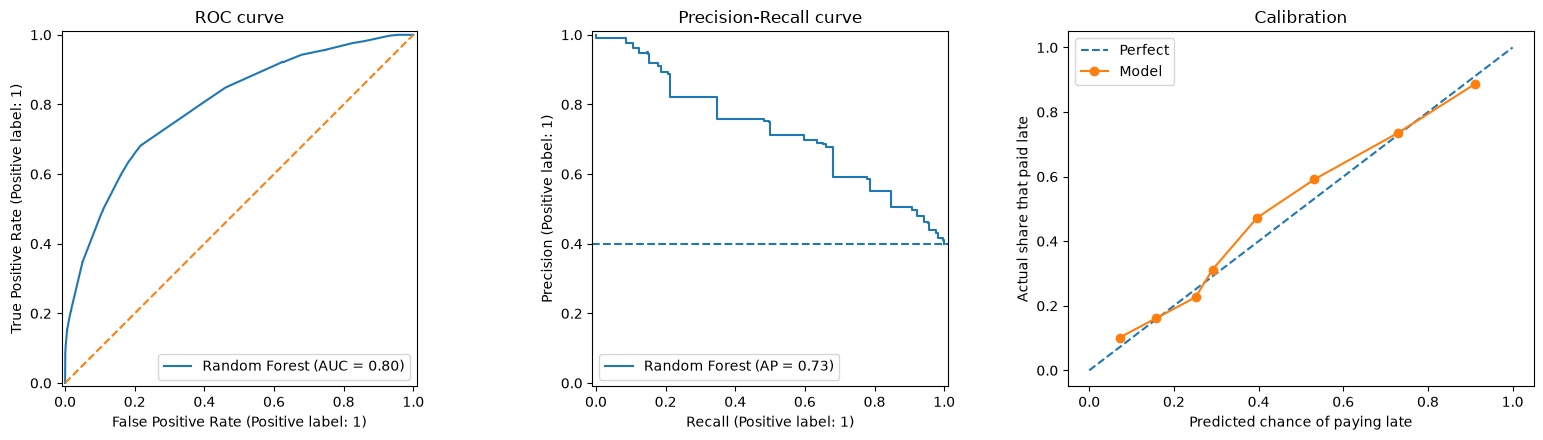

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[0], name=CHOSEN)
axes[0].plot([0, 1], [0, 1], linestyle='--')
PrecisionRecallDisplay.from_predictions(y_test, p_test, ax=axes[1], name=CHOSEN)
axes[1].axhline(y_test.mean(), linestyle='--', label='Baseline')
frac_pos, mean_pred = calibration_curve(y_test, p_test, n_bins=8, strategy='quantile')
axes[2].plot([0, 1], [0, 1], linestyle='--', label='Perfect')
axes[2].plot(mean_pred, frac_pos, marker='o', label='Model')
axes[2].set_xlabel('Predicted chance of paying late')
axes[2].set_ylabel('Actual share that paid late')
axes[2].legend()
axes[0].set_title('ROC curve'); axes[1].set_title('Precision-Recall curve'); axes[2].set_title('Calibration')
plt.tight_layout()
plt.savefig(FIGS + 'invoices_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()

**Explainability**

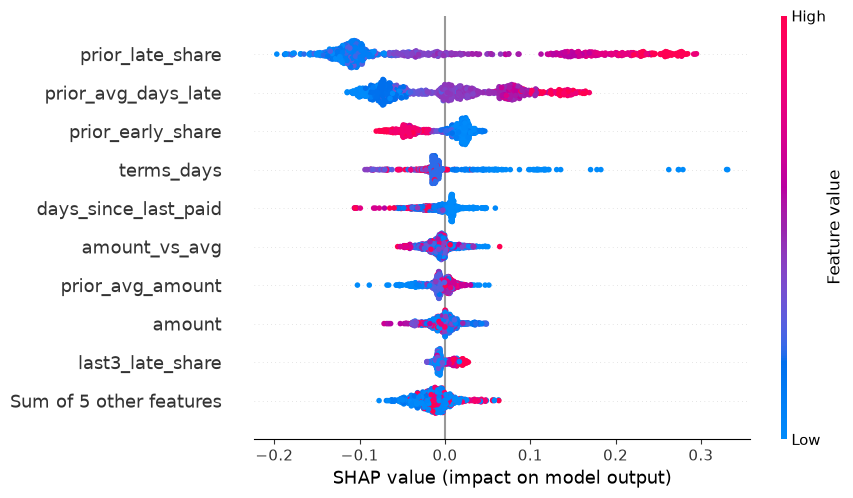

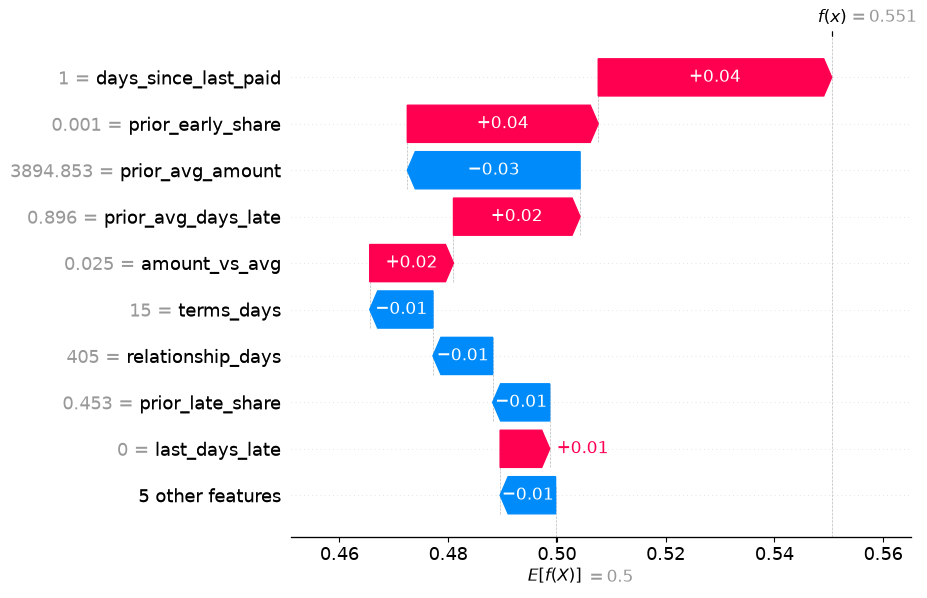

In [16]:
explain_name = 'Random Forest' if CHOSEN in ('Random Forest', 'Average of RF and GB') else 'Gradient Boosting'
explain_model = tuned[explain_name].named_steps['model']
sample = X_test.fillna(-1).sample(1000, random_state=SEED)
sv = shap.TreeExplainer(explain_model)(sample)
if sv.values.ndim == 3:
    sv = sv[:, :, 1]
shap.plots.beeswarm(sv, show=False)
plt.savefig(FIGS + 'invoices_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()
shap.plots.waterfall(sv[0], show=False)
plt.savefig(FIGS + 'invoices_shap_one_client.png', dpi=150, bbox_inches='tight')
plt.show()

**Save**

In [17]:
joblib.dump({'calibrated_models': calibrated, 'chosen': CHOSEN, 'features': FEATURES,
             'cutoffs': (LOW, HIGH)}, MODELS + 'invoice_method_test.joblib')
results.round(4).to_csv(REPORTS + 'invoices_results.csv')
cv_table.to_csv(REPORTS + 'invoices_cross_validation.csv')
print('Saved model, results and figures')

Saved model, results and figures


**Limitations and diagnostic findings.**
 The invoices are from a large multinational, not a Kenyan SME. Payment dates were withheld for every invoice from March 2020 onwards, and for invoices issued in October and November 2019 no payment after 31 December 2019 was recorded, so the slowest payers in those months are missing from the file.

**Academic statement.** 
Applying the same pipeline to 39,158 business-to-business invoices, a calibrated Random Forest achieved ROC-AUC 0.80 and PR-AUC 0.73 on a held-out later period, against a baseline of 0.40. Clients placed in the High tier paid late 76% of the time, against 13% in the Low tier.

**Explainability.** The customer's own payment history again dominates.

**Business analysis**. On real invoices the method separates payers far more sharply than on consumer loans. This is the closest test to what the prototype will actually do.
**Recommendation.** Retrain on Kenyan invoices as the prototype collects them, since the method clearly transfers to invoice data.